**Análisis y Modelado de Datos de Accidentes de Tráfico**

#1. Resumen

Este documento presenta un análisis detallado de un conjunto de datos sobre accidentes de tráfico. Se realiza un preprocesamiento exhaustivo, exploración de datos, generación de características y modelado predictivo. Se emplean técnicas de balanceo de clases, ingeniería de características y algoritmos de aprendizaje automático para predecir la lesividad de los accidentes.

#2. Estado del Arte

El análisis de accidentes de tráfico ha sido ampliamente estudiado con técnicas de Machine Learning. Modelos como Random Forest, XGBoost y redes neuronales han demostrado ser efectivos para la predicción de gravedad de accidentes. Sin embargo, el desbalance de clases y la calidad de los datos son desafíos recurrentes. Técnicas como SMOTE y codificación de variables categóricas han sido utilizadas para mejorar la precisión y generalización de los modelos.

#3. Objetivos

Los objetivos principales de este trabajo son:

-Realizar una exploración y limpieza de datos eficiente.

-Aplicar técnicas de ingeniería de características para mejorar el modelo.

-Entrenar y evaluar modelos predictivos de Machine Learning.

-Comparar las predicciones con los valores reales y analizar la precisión del modelo.

#4. Desarrollo

4.1 Importación de Librerías y Carga de Datos

In [ ]:
import numpy as np # Importamos la librería NumPy, que se usa principalmente para trabajar con arreglos (arrays) y operaciones matemáticas de alto rendimiento.
import pandas as pd # Importamos Pandas, una librería fundamental para la manipulación y análisis de datos, en especial para trabajar con estructuras de datos como DataFrames.
import matplotlib.pyplot as plt # Importamos matplotlib.pyplot, que se utiliza para crear gráficos y visualizaciones en 2D de forma fácil.
import seaborn as sns # Importamos seaborn, una librería de visualización de datos en Python.
from sklearn import metrics  # Importa el módulo 'metrics' de scikit-learn para evaluar el rendimiento del modelo.
from sklearn.metrics import accuracy_score, roc_curve, auc # Importa funciones específicas para calcular la precisión, la curva ROC y el AUC.

CARGA DE DATOS

In [ ]:
# Rutas a los datos (ajusta los enlaces o rutas a tu entorno)
train_path = 'https://drive.google.com/uc?export=download&id=16nCIJ5xXYYSGK8I7eEXPgboOh9mEkhc9'
test_path  = 'https://drive.google.com/uc?export=download&id=1OeP-1Iig6bm0uSF4ifMHJaLBOJSz-Mzn'

df_train = pd.read_csv(train_path, low_memory=False)
df_test  = pd.read_csv(test_path, low_memory=False)

df_train.head()

,num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,lesividad,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga,id
0,2020S000038,01/01/2020,22:35:00,CALL. VALLE DE TORANZO / CALL. SIERRA DE PAJAREJO,3,9.0,MONCLOA-ARAVACA,Caída,Despejado,Ciclomotor,Conductor,De 21 a 24 años,Mujer,2,432586,4479981,N,NaN,1
1,2020S000067,01/01/2020,18:40:00,PLAZA. BEATA MARIA ANA DE JESUS / PASEO. DELICIAS,9,2.0,ARGANZUELA,Caída,NaN,Motocicleta hasta 125cc,Conductor,De 35 a 39 años,Hombre,3,441035,4471710,N,NaN,2
2,2020S000021,01/01/2020,9:30:00,"CALL. LUIS BUÑUEL, 2",2,13.0,PUENTE DE VALLECAS,Choque contra obstáculo fijo,Despejado,Turismo,Conductor,De 18 a 20 años,Hombre,3,445287,4470975,N,NaN,3
3,2020S000047,01/01/2020,12:39:00,"CALL. ANSAR, 82",82,10.0,LATINA,Choque contra obstáculo fijo,Despejado,Turismo,Conductor,De 18 a 20 años,Hombre,3,436922,4472874,N,NaN,4
4,2020S000043,01/01/2020,14:14:00,"AUTOV. M-30, KM 11,800 CALZADA 2",+01200E,13.0,PUENTE DE VALLECAS,Alcance,Despejado,Turismo,Conductor,De 40 a 44 años,Hombre,3,442032,4470533,N,NaN,5


3. Exploración y Limpieza de Datos

Eliminación de Registros Repetidos

Se eliminan registros en df_train cuyos num_expediente estén en df_test, evitando el sobreajuste.

In [ ]:
df_train = df_train[~df_train['num_expediente'].isin(df_test['num_expediente'])]

4. Análisis Exploratorio de Datos (EDA)

In [ ]:
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 86012 entries, 0 to 90908
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   num_expediente        86012 non-null  object 
 1   fecha                 86012 non-null  object 
 2   hora                  86012 non-null  object 
 3   localizacion          86012 non-null  object 
 4   numero                86009 non-null  object 
 5   cod_distrito          86009 non-null  float64
 6   distrito              86009 non-null  object 
 7   tipo_accidente        86010 non-null  object 
 8   estado_meteorológico  84164 non-null  object 
 9   tipo_vehiculo         85886 non-null  object 
 10  tipo_persona          86012 non-null  object 
 11  rango_edad            86012 non-null  object 
 12  sexo                  86012 non-null  object 
 13  lesividad             86012 non-null  int64  
 14  coordenada_x_utm      85992 non-null  object 
 15  coordenada_y_utm      85

In [ ]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
cod_distrito,86009.0,9.658175,5.677516,1.0,5.00,9.0,14.00,21.0
lesividad,86012.0,2.783949,0.464379,1.0,3.00,3.0,3.00,3.0
positiva_droga,434.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
id,86012.0,45356.923918,26261.640333,1.0,22618.75,45247.5,68110.25,90909.0


In [ ]:
df_test.describe().T

,count,mean,std,min,25%,50%,75%,max
cod_distrito,3442.0,9.566241e+00,5.627996,1.0,5.00,9.0,14.00,21.0
coordenada_x_utm,3441.0,4.421255e+05,3332.944914,429980.0,440040.00,441833.0,443967.00,454169.0
coordenada_y_utm,3441.0,4.474817e+06,3883.448945,4464444.0,4471875.00,4474874.0,4477479.00,4489234.0
positiva_droga,17.0,1.000000e+00,0.000000,1.0,1.00,1.0,1.00,1.0
id,3442.0,9.263050e+04,993.764140,90910.0,91770.25,92630.5,93490.75,94351.0


# Análisis de los porcentajes de accidentes basados en el sexo dado

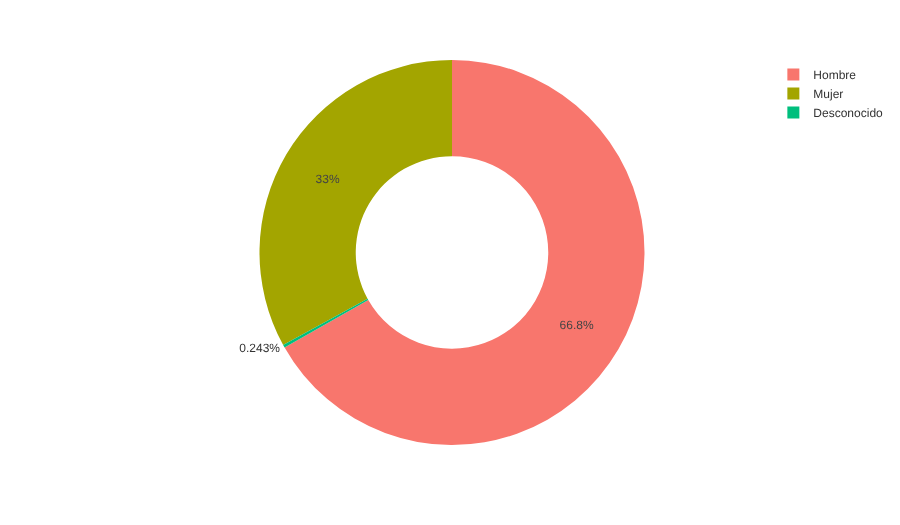

In [ ]:

import plotly.express as px
px.pie(df_train, df_train['sexo'], df_train['numero'], template='ggplot2',hole=0.5)


# Análisis de los porcentajes de lesividades encontrados

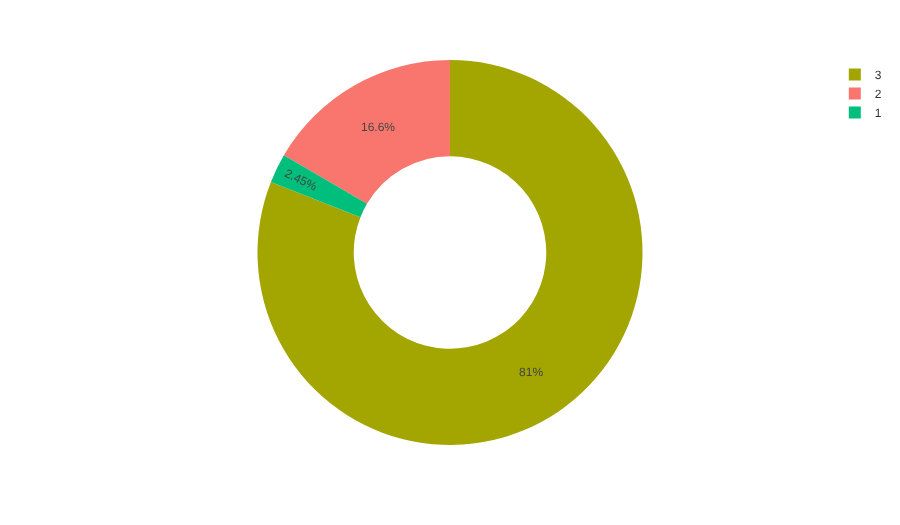

In [ ]:

px.pie(df_train,df_train['lesividad'],df_train['numero'],color='lesividad',template='ggplot2',hole=0.5)

Podemos observar que la lesividad de nivel 3 está sesgado en el dataset

# Crear visualizaciones de la distribución de 'lesividad' para cada variable categórica

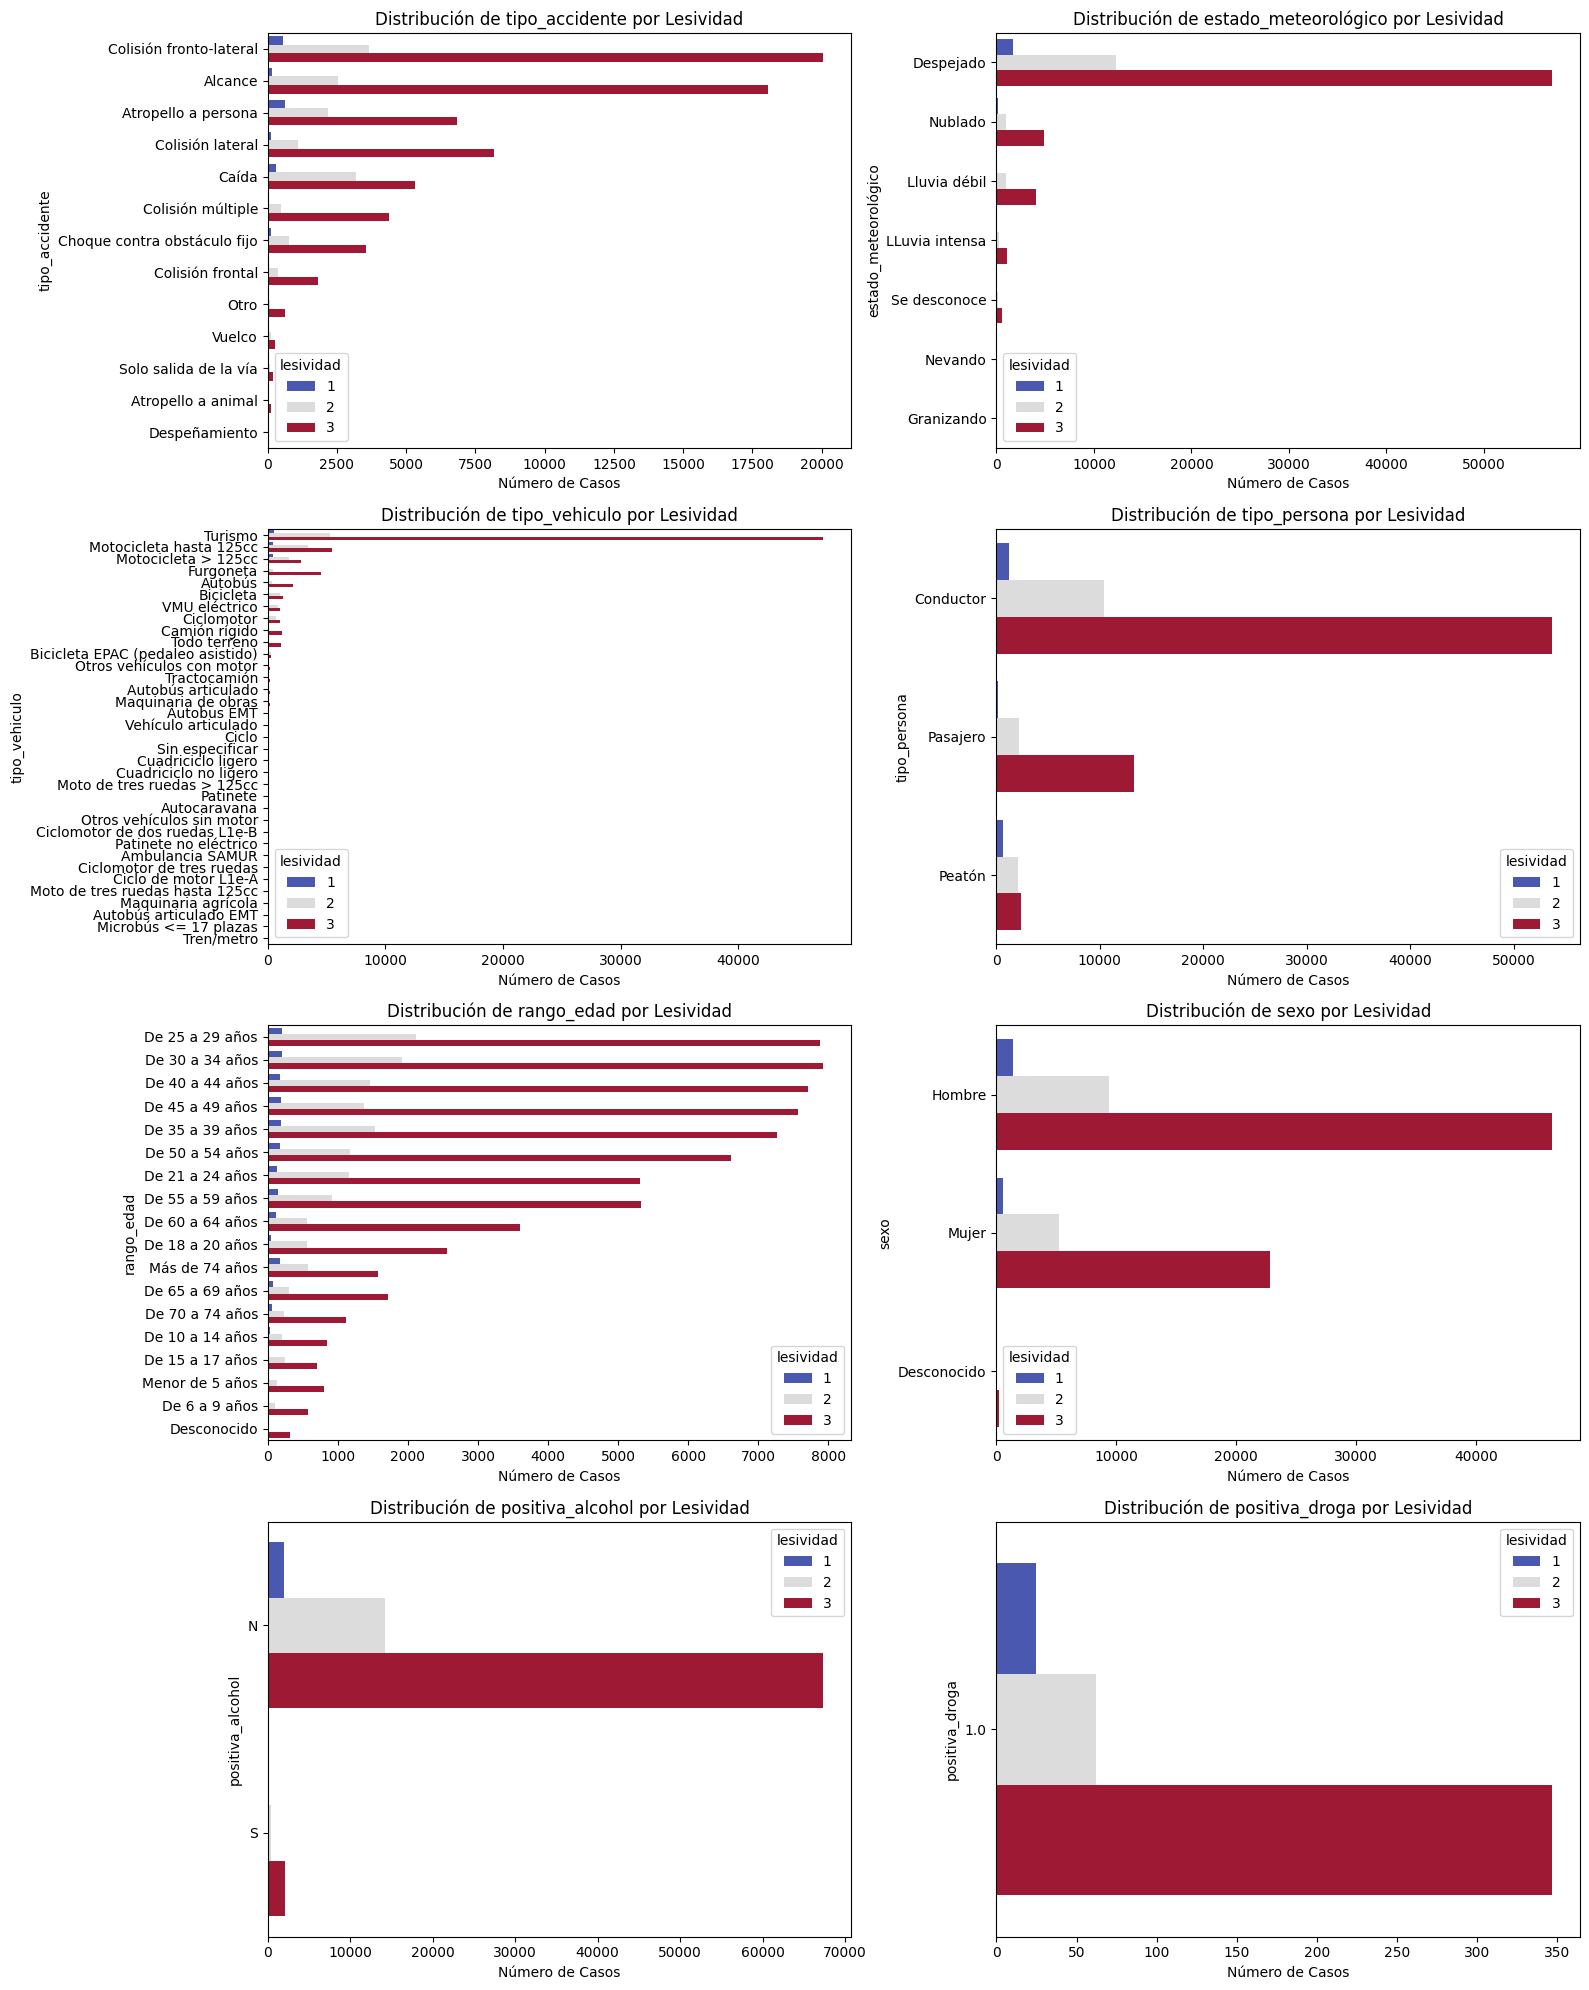

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definir las variables categóricas a analizar
categorical_vars = [
    "tipo_accidente",
    "estado_meteorológico",
    "tipo_vehiculo",
    "tipo_persona",
    "rango_edad",
    "sexo",
    "positiva_alcohol",
    "positiva_droga"
]


fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 20))
axes = axes.flatten()

for i, var in enumerate(categorical_vars):
    sns.countplot(
        data=df_train,
        y=var,
        hue="lesividad",
        palette="coolwarm",
        order=df_train[var].value_counts().index,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribución de {var} por Lesividad")
    axes[i].set_xlabel("Número de Casos")
    axes[i].set_ylabel(var)

plt.tight_layout()
plt.show()


#Análisis del numero de instancias dependiento del tipo de accidentes

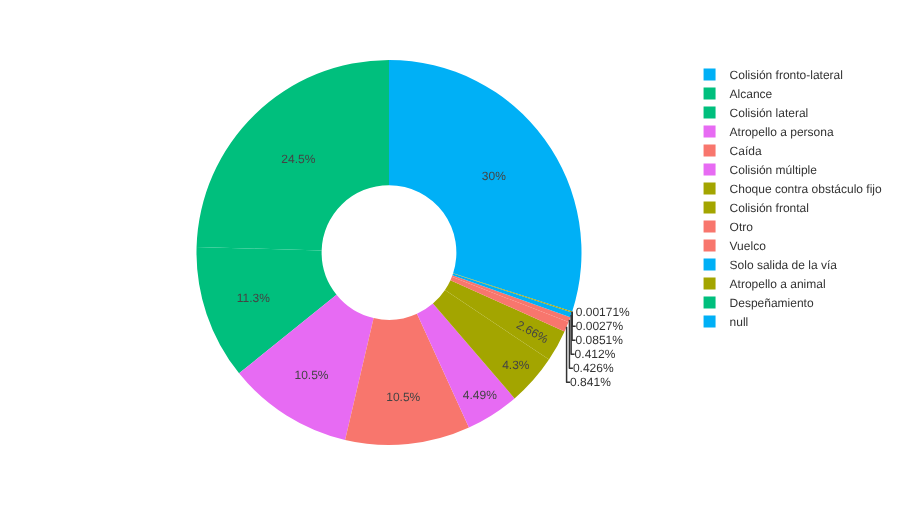

In [ ]:
px.pie(df_train,df_train['tipo_accidente'],df_train['numero'],color='tipo_accidente',template='ggplot2',hole=0.35)

# Graficar los accidentes por día de la semana y transformar el formato de la fecha

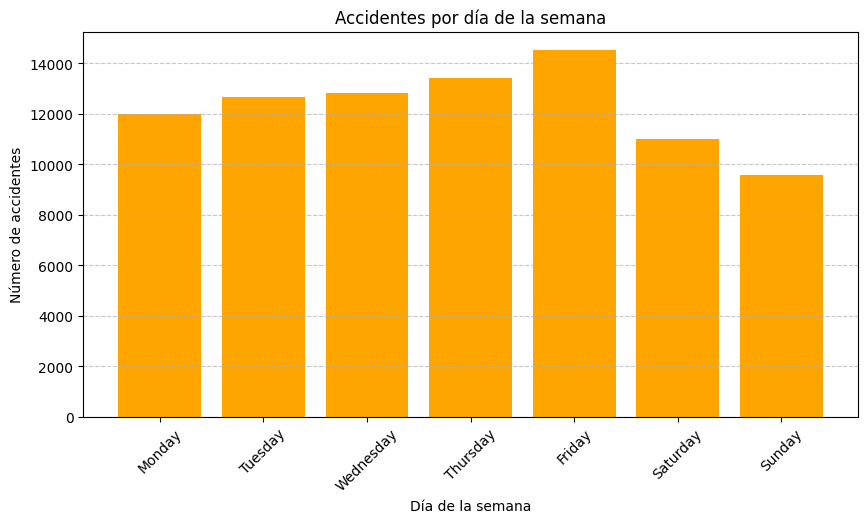

In [ ]:
import matplotlib.pyplot as plt

# Convertir la columna 'fecha' a formato datetime
df_train['fecha'] = pd.to_datetime(df_train['fecha'], format='%d/%m/%Y')
df_test['fecha'] = pd.to_datetime(df_test['fecha'], format='%d/%m/%Y')

# Extraer el día de la semana
df_train['dia_semana'] = df_train['fecha'].dt.day_name()
df_test['dia_semana'] = df_test['fecha'].dt.day_name()

# Contar accidentes por día de la semana
accidentes_por_dia = df_train['dia_semana'].value_counts()

# Ordenar los días en orden correcto
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
accidentes_por_dia = accidentes_por_dia.reindex(orden_dias)

# Graficar los accidentes por día de la semana
plt.figure(figsize=(10, 5))
plt.bar(accidentes_por_dia.index, accidentes_por_dia.values, color='orange')
plt.xlabel("Día de la semana")
plt.ylabel("Número de accidentes")
plt.title("Accidentes por día de la semana")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


In [ ]:
df_test.head()

,num_expediente,fecha,hora,localizacion,numero,cod_distrito,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,coordenada_x_utm,coordenada_y_utm,positiva_alcohol,positiva_droga,id,dia_semana
0,2022S000029,2022-01-01,6:25:00,"AVDA. FILIPINAS, 50",50,7.0,CHAMBERÍ,Alcance,Despejado,Turismo,Conductor,De 35 a 39 años,Hombre,440125.0,4477019.0,N,NaN,90910,Saturday
1,2024S000070,2024-01-01,22:02:00,CALL. MARSELLA / CALL. ZURICH,29,20.0,SAN BLAS-CANILLEJAS,Colisión fronto-lateral,Despejado,Turismo,Conductor,De 21 a 24 años,Hombre,448270.0,4474626.0,N,NaN,90911,Monday
2,2020S002443,2020-02-01,21:05:00,AVDA. CONCHA ESPINA / CALL. SERRANO,49,5.0,CHAMARTÍN,Caída,Despejado,Autobús,Pasajero,De 25 a 29 años,Mujer,442257.0,4478120.0,N,NaN,90912,Saturday
3,2021S001350,2021-02-01,20:48:00,"CALL. COSTA BRAVA, 23",23,8.0,FUENCARRAL-EL PARDO,Choque contra obstáculo fijo,Se desconoce,Motocicleta > 125cc,Conductor,De 25 a 29 años,Hombre,440378.0,4483108.0,N,NaN,90913,Monday
4,2022S002196,2022-02-01,1:10:00,"PASEO. PRADO, 22",22,1.0,CENTRO,Colisión fronto-lateral,Despejado,Turismo,Conductor,De 35 a 39 años,Hombre,441157.0,4473838.0,N,NaN,90914,Tuesday


# Graficar el rango de edad de los accidentes producidos

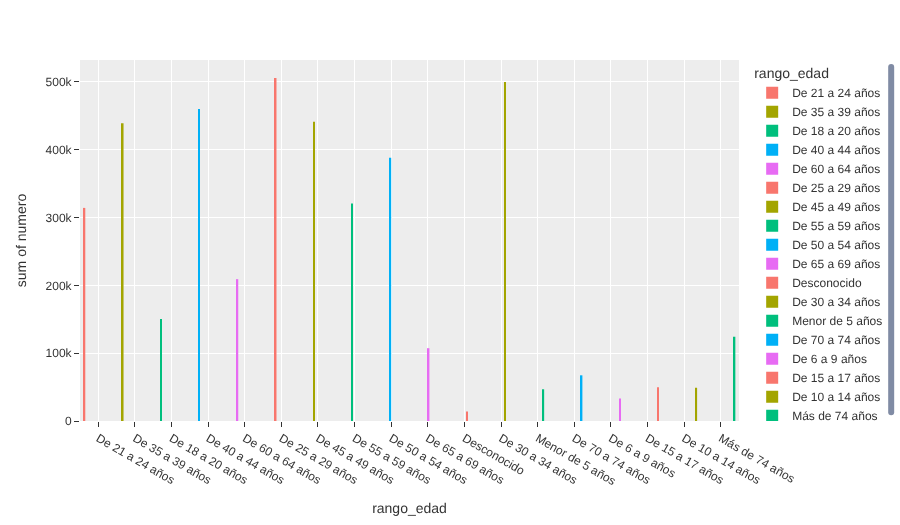

In [ ]:
px.histogram(df_train,df_train['rango_edad'],df_train['numero'],color='rango_edad',template='ggplot2')

# Graficar los accidentes dependiento del tipo de persona

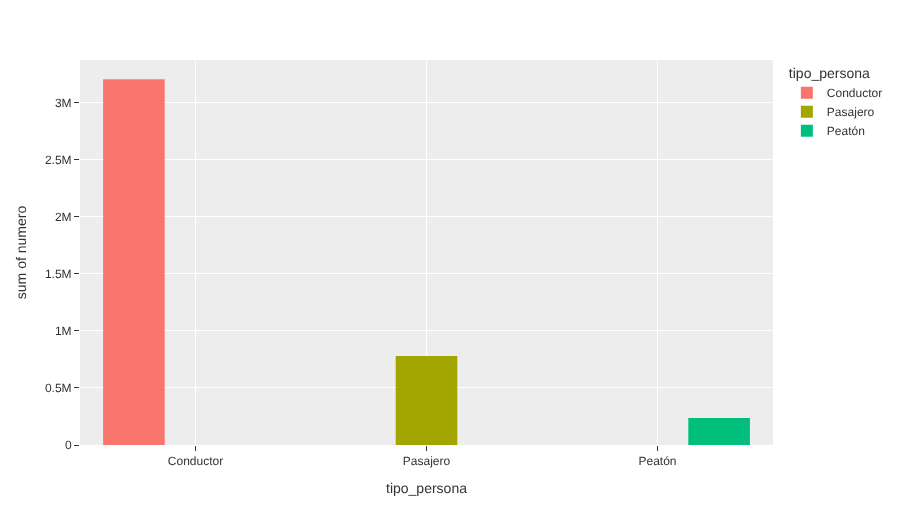

In [ ]:
px.histogram(df_train,df_train['tipo_persona'],df_train['numero'],color='tipo_persona',template='ggplot2')

# Graficar los accidentes según el vehículo

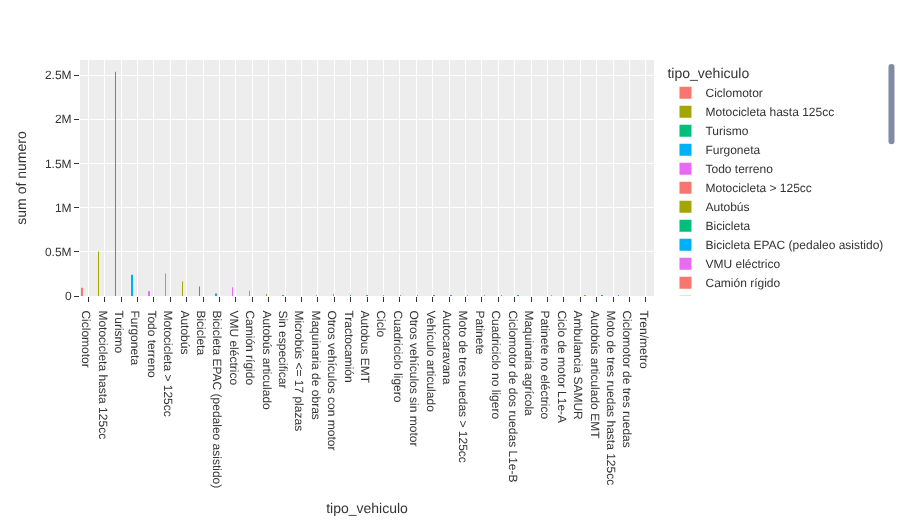

In [ ]:
px.histogram(df_train,df_train['tipo_vehiculo'],df_train['numero'],color='tipo_vehiculo',template='ggplot2')

# Graficar los accidentes según la hora en la que ocurre y transformar el formato de la hora

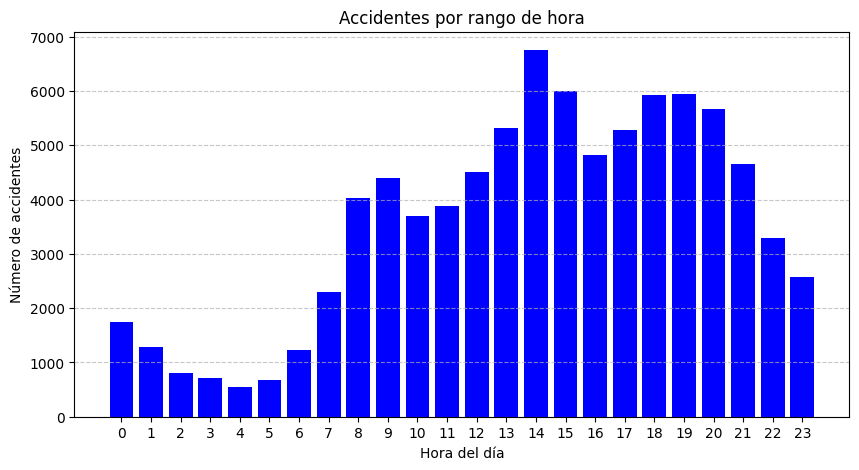

In [ ]:
df_train['hora_num'] = pd.to_datetime(df_train['hora'], format='%H:%M:%S').dt.hour
df_test['hora_num'] = pd.to_datetime(df_test['hora'], format='%H:%M:%S').dt.hour

# Contar accidentes por hora del día
accidentes_por_hora = df_train['hora_num'].value_counts().sort_index()


# Graficar los accidentes por hora del día
plt.figure(figsize=(10, 5))
plt.bar(accidentes_por_hora.index, accidentes_por_hora.values, color='blue')
plt.xlabel("Hora del día")
plt.ylabel("Número de accidentes")
plt.title("Accidentes por rango de hora")
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Transformar el formato de las coordenadas a latitud y longitud para mostrarlas de manera mucho más fácil

In [ ]:
import pandas as pd
import numpy as np
from pyproj import Transformer

# Crear el transformador UTM -> WGS84 (Lat/Lon) para la zona 30N (Madrid)
transformer = Transformer.from_crs("epsg:32630", "epsg:4326", always_xy=True)

# Función para convertir coordenadas UTM a latitud/longitud en un DataFrame sin eliminar filas
def convertir_coordenadas(df):
    # Asegurar que las coordenadas sean numéricas
    df['coordenada_x_utm'] = pd.to_numeric(df['coordenada_x_utm'], errors='coerce')
    df['coordenada_y_utm'] = pd.to_numeric(df['coordenada_y_utm'], errors='coerce')

    # 🔹 Sustituir valores nulos con la media en lugar de eliminarlos
    df['coordenada_x_utm'].fillna(df['coordenada_x_utm'].mean(), inplace=True)
    df['coordenada_y_utm'].fillna(df['coordenada_y_utm'].mean(), inplace=True)

    # Convertir a arrays NumPy para optimizar rendimiento
    x_utm = df['coordenada_x_utm'].values
    y_utm = df['coordenada_y_utm'].values

    # Aplicar transformación en bloque
    longitudes, latitudes = transformer.transform(x_utm, y_utm)

    # Sustituir las coordenadas UTM con latitud y longitud en el DataFrame
    df['longitud'] = longitudes
    df['latitud'] = latitudes

    # Eliminar las columnas originales de coordenadas UTM si ya no son necesarias
    df.drop(columns=['coordenada_x_utm', 'coordenada_y_utm'], inplace=True)

# Aplicar la conversión en df_train y df_test
convertir_coordenadas(df_train)
convertir_coordenadas(df_test)

# Verificar que ya no haya valores nulos en latitud y longitud
df_train['latitud'].fillna(df_train['latitud'].mean(), inplace=True)
df_train['longitud'].fillna(df_train['longitud'].mean(), inplace=True)
df_test['latitud'].fillna(df_test['latitud'].mean(), inplace=True)
df_test['longitud'].fillna(df_test['longitud'].mean(), inplace=True)

# Mostrar las primeras filas con los cambios aplicados en df_train y df_test
print("✅ Conversión completada sin eliminar filas.")

print("\n🔹 Datos de df_train:")
display(df_train[['latitud', 'longitud']].head())

print("\n🔹 Datos de df_test:")
display(df_test[['latitud', 'longitud']].head())


✅ Conversión completada sin eliminar filas.

🔹 Datos de df_train:


<ipython-input-48-84929308702d>:15: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



<ipython-input-48-84929308702d>:16: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or d

,latitud,longitud
0,40.467771,-3.795212
1,40.393905,-3.694789
2,40.387574,-3.644627
3,40.404089,-3.743364
4,40.383372,-3.682935



🔹 Datos de df_test:


,latitud,longitud
0,40.441666,-3.706010
1,40.420655,-3.609780
2,40.451735,-3.680973
3,40.496536,-3.703599
4,40.413084,-3.693548


#Visualiacion de los accidentes en un mapa de Madrid con la API de OpenStreet

In [ ]:
import folium
from folium.plugins import HeatMap

# Crear un mapa centrado en Madrid
madrid_center = [40.4168, -3.7038]  # Coordenadas aproximadas de Madrid
m = folium.Map(location=madrid_center, zoom_start=12)

# Asegurar que los datos sean numéricos y eliminar filas sin coordenadas
df_train[['latitud', 'longitud']] = df_train[['latitud', 'longitud']].apply(pd.to_numeric, errors='coerce')
df_mapa = df_train.dropna(subset=['latitud', 'longitud'])

# Agregar puntos de accidentes al mapa
for _, row in df_mapa.iterrows():
    folium.CircleMarker(
        location=[row['latitud'], row['longitud']],
        radius=3,
        color='red',
        fill=True,
        fill_color='red',
        fill_opacity=0.2,
    ).add_to(m)

# Mostrar el mapa
m


[Interactive Folium heat map of accident locations in Madrid removed from the saved notebook because of its size (130 MB). Run the cell to regenerate it.]


#Comenzams a tratar los valores nulos

In [ ]:
df_train.isnull().sum()

,0
num_expediente,0
fecha,0
hora,0
localizacion,0
numero,3
cod_distrito,3
distrito,3
tipo_accidente,2
estado_meteorológico,1848
tipo_vehiculo,126


In [ ]:
# Mostrar valores nulos antes de eliminarlos
missing_train = df_train.isnull().sum().sort_values(ascending=False)
print("\nValores nulos (df_train) antes de eliminar:")
print(missing_train[missing_train > 0])

# Eliminar filas con valores nulos en cualquier columna
df_train_clean = df_train.dropna().copy()

# Verificar nuevamente valores nulos
missing_train_after = df_train_clean.isnull().sum().sort_values(ascending=False)
print("\nValores nulos (df_train) después de eliminar:")
print(missing_train_after[missing_train_after > 0])

missing_train = df_test.isnull().sum().sort_values(ascending=False)
print("\nValores nulos (df_test) antes de eliminar:")
print(missing_train[missing_train > 0])

# Eliminar filas con valores nulos en cualquier columna
df_train_clean = df_test.dropna().copy()

# Verificar nuevamente valores nulos
missing_train_after = df_train_clean.isnull().sum().sort_values(ascending=False)
print("\nValores nulos (df_test) después de eliminar:")
print(missing_train_after[missing_train_after > 0])


Valores nulos (df_train) antes de eliminar:
positiva_droga          85578
estado_meteorológico     1848
tipo_vehiculo             126
numero                      3
cod_distrito                3
distrito                    3
tipo_accidente              2
dtype: int64

Valores nulos (df_train) después de eliminar:
Series([], dtype: int64)

Valores nulos (df_test) antes de eliminar:
positiva_droga          3425
estado_meteorológico      68
tipo_vehiculo              8
dtype: int64

Valores nulos (df_test) después de eliminar:
Series([], dtype: int64)


In [ ]:
df_train.shape

(86012, 21)

In [ ]:
df_test.shape

(3442, 20)

#Eliminamos la hora, ya que tenemos el numero de la hora en el dataset, el numero de expediente y el cod_distrito.

In [ ]:
df_train.drop(['hora','num_expediente','cod_distrito'],axis=1,inplace=True)
df_test.drop(['hora','num_expediente','cod_distrito'],axis=1,inplace=True)

#Comenzamos a tratar los valores duplicados

In [ ]:
duplicados_train = df_train.duplicated()
n_duplicados_train = duplicados_train.sum()
if n_duplicados_train > 0:
    df_train.drop_duplicates(inplace=True)

duplicados_train = df_test.duplicated()
n_duplicados_train = duplicados_train.sum()
if n_duplicados_train > 0:
    df_test.drop_duplicates(inplace=True)

Rellenar valores faltantes

In [ ]:
categorical_cols = ['estado_meteorológico', 'tipo_vehiculo']
for col in categorical_cols:
    df_train[col].fillna('Desconocido', inplace=True)
    df_test[col].fillna('Desconocido', inplace=True)

for col in ['latitud', 'longitud']:
    df_train[col].fillna(df_train[col].mean(), inplace=True)
    df_test[col].fillna(df_test[col].mean(), inplace=True)

df_train['positiva_droga'].fillna(0, inplace=True)
df_test['positiva_droga'].fillna(0, inplace=True)

<ipython-input-57-91f09576ec7c>:3: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.



<ipython-input-57-91f09576ec7c>:4: FutureWarning:

A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[

#Eliminamos los valores desconocidos

In [ ]:
import numpy as np

# Convertir valores problemáticos a NaN en df_train y df_test
df_train.replace(["nan", "Desconocido", "Se desconoce"], np.nan, inplace=True)
df_test.replace(["nan", "Desconocido", "Se desconoce"], np.nan, inplace=True)



# Eliminar filas que tengan NaN después de la conversión
df_train.dropna(inplace=True)


# Verificar que ya no haya valores nulos
print("\nValores nulos (df_train) después de limpiar:")
print(df_train.isnull().sum().sort_values(ascending=False).head(10))

# Comprobar que los valores problemáticos han sido eliminados
for col in ['estado_meteorológico', 'tipo_vehiculo','sexo','tipo_accidente']:
    print(f"\nValores únicos en {col} después de limpiar:")
    print(df_train[col].unique())


Valores nulos (df_train) después de limpiar:
fecha               0
localizacion        0
longitud            0
hora_num            0
dia_semana          0
id                  0
positiva_droga      0
positiva_alcohol    0
lesividad           0
sexo                0
dtype: int64

Valores únicos en estado_meteorológico después de limpiar:
['Despejado' 'Lluvia débil' 'Nublado' 'LLuvia intensa' 'Granizando'
 'Nevando']

Valores únicos en tipo_vehiculo después de limpiar:
['Ciclomotor' 'Turismo' 'Motocicleta hasta 125cc' 'Furgoneta'
 'Todo terreno' 'Motocicleta > 125cc' 'Autobús' 'Bicicleta'
 'Bicicleta EPAC (pedaleo asistido)' 'VMU eléctrico' 'Camión rígido'
 'Autobús articulado' 'Sin especificar' 'Microbús <= 17 plazas'
 'Maquinaria de obras' 'Otros vehículos con motor' 'Tractocamión'
 'Autobus EMT' 'Ciclo' 'Cuadriciclo ligero' 'Otros vehículos sin motor'
 'Vehículo articulado' 'Autocaravana' 'Moto de tres ruedas > 125cc'
 'Patinete' 'Cuadriciclo no ligero' 'Ciclomotor de dos ruedas L1e-B

In [ ]:
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 82984 entries, 0 to 90908
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   fecha                 82984 non-null  datetime64[ns]
 1   localizacion          82984 non-null  object        
 2   numero                82984 non-null  object        
 3   distrito              82984 non-null  object        
 4   tipo_accidente        82984 non-null  object        
 5   estado_meteorológico  82984 non-null  object        
 6   tipo_vehiculo         82984 non-null  object        
 7   tipo_persona          82984 non-null  object        
 8   rango_edad            82984 non-null  object        
 9   sexo                  82984 non-null  object        
 10  lesividad             82984 non-null  int64         
 11  positiva_alcohol      82984 non-null  object        
 12  positiva_droga        82984 non-null  float64       
 13  id                   

#Transformación de las variables categoricas

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OrdinalEncoder

# Copiar los DataFrames originales
df_train_encoded = df_train.copy()
df_test_encoded = df_test.copy()

# 🔹 Lista de columnas categóricas

categorical_cols = [
     'tipo_accidente', 'estado_meteorológico', 'tipo_vehiculo',
    'tipo_persona', 'rango_edad', 'sexo', 'positiva_alcohol', 'dia_semana', 'localizacion','distrito'
    ,'numero'
]


# 🔥 Aplicar Ordinal Encoding con manejo de valores desconocidos
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Transformar las columnas categóricas
df_train_encoded[categorical_cols] = encoder.fit_transform(df_train_encoded[categorical_cols])
df_test_encoded[categorical_cols] = encoder.transform(df_test_encoded[categorical_cols])  # Sin `fit()`, solo `transform()`

# Mostrar los primeros valores transformados
print("Datos transformados de df_train:")
display(df_train_encoded.head())

# Mostrar tipos de datos después de la conversión
print("\nTipos de datos después de la conversión:")
print(df_train_encoded.dtypes)


Datos transformados de df_train:


,fecha,localizacion,numero,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,lesividad,positiva_alcohol,positiva_droga,id,dia_semana,hora_num,longitud,latitud
0,2020-01-01,21312.0,1257.0,10.0,3.0,0.0,11.0,0.0,3.0,1.0,2,0.0,0.0,1,6.0,22,-3.795212,40.467771
2,2020-01-01,15671.0,971.0,12.0,4.0,0.0,32.0,0.0,2.0,0.0,3,0.0,0.0,3,6.0,9,-3.644627,40.387574
3,2020-01-01,7919.0,1760.0,9.0,4.0,0.0,32.0,0.0,2.0,0.0,3,0.0,0.0,4,6.0,12,-3.743364,40.404089
4,2020-01-01,2163.0,61.0,12.0,0.0,0.0,32.0,0.0,7.0,0.0,3,0.0,0.0,5,6.0,14,-3.682935,40.383372
5,2020-01-01,5436.0,1331.0,20.0,6.0,0.0,32.0,0.0,6.0,1.0,3,0.0,0.0,6,6.0,1,-3.689881,40.362096



Tipos de datos después de la conversión:
fecha                   datetime64[ns]
localizacion                   float64
numero                         float64
distrito                       float64
tipo_accidente                 float64
estado_meteorológico           float64
tipo_vehiculo                  float64
tipo_persona                   float64
rango_edad                     float64
sexo                           float64
lesividad                        int64
positiva_alcohol               float64
positiva_droga                 float64
id                               int64
dia_semana                     float64
hora_num                         int32
longitud                       float64
latitud                        float64
dtype: object


In [ ]:
df_train = df_train_encoded.copy()

# Verificar la transformación
df_train.head()

,fecha,localizacion,numero,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,lesividad,positiva_alcohol,positiva_droga,id,dia_semana,hora_num,longitud,latitud
0,2020-01-01,21312.0,1257.0,10.0,3.0,0.0,11.0,0.0,3.0,1.0,2,0.0,0.0,1,6.0,22,-3.795212,40.467771
2,2020-01-01,15671.0,971.0,12.0,4.0,0.0,32.0,0.0,2.0,0.0,3,0.0,0.0,3,6.0,9,-3.644627,40.387574
3,2020-01-01,7919.0,1760.0,9.0,4.0,0.0,32.0,0.0,2.0,0.0,3,0.0,0.0,4,6.0,12,-3.743364,40.404089
4,2020-01-01,2163.0,61.0,12.0,0.0,0.0,32.0,0.0,7.0,0.0,3,0.0,0.0,5,6.0,14,-3.682935,40.383372
5,2020-01-01,5436.0,1331.0,20.0,6.0,0.0,32.0,0.0,6.0,1.0,3,0.0,0.0,6,6.0,1,-3.689881,40.362096


In [ ]:
df_test = df_test_encoded.copy()

# Verificar la transformación
df_test.head()

,fecha,localizacion,numero,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,positiva_alcohol,positiva_droga,id,dia_semana,hora_num,longitud,latitud
0,2022-01-01,4158.0,1574.0,5.0,0.0,0.0,32.0,0.0,6.0,0.0,0.0,0.0,90910,2.0,6,-3.706010,40.441666
1,2024-01-01,16320.0,1205.0,15.0,6.0,0.0,32.0,0.0,3.0,0.0,0.0,0.0,90911,1.0,22,-3.609780,40.420655
2,2020-02-01,3731.0,1562.0,4.0,3.0,0.0,2.0,1.0,4.0,1.0,0.0,0.0,90912,2.0,21,-3.680973,40.451735
3,2021-02-01,10976.0,1059.0,7.0,4.0,-1.0,22.0,0.0,4.0,0.0,0.0,0.0,90913,1.0,20,-3.703599,40.496536
4,2022-02-01,25033.0,1028.0,3.0,6.0,0.0,32.0,0.0,6.0,0.0,0.0,0.0,90914,5.0,1,-3.693548,40.413084


#Transformación de la variable fecha

In [ ]:
# Extraer componentes de la fecha
df_train['año'] = df_train['fecha'].dt.year
df_train['mes'] = df_train['fecha'].dt.month
df_train['dia'] = df_train['fecha'].dt.day
df_train['dia_semana'] = df_train['fecha'].dt.weekday  # 0=Lunes, 6=Domingo
df_train['es_fin_de_semana'] = df_train['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

# Eliminar la columna original si ya no es necesaria
df_train.drop(columns=['fecha'], inplace=True)

# Mostrar los primeros valores transformados
print(df_train[['año', 'mes', 'dia', 'dia_semana', 'es_fin_de_semana']].head())

# Extraer componentes de la fecha
df_test['año'] = df_test['fecha'].dt.year
df_test['mes'] = df_test['fecha'].dt.month
df_test['dia'] = df_test['fecha'].dt.day
df_test['dia_semana'] = df_test['fecha'].dt.weekday  # 0=Lunes, 6=Domingo
df_test['es_fin_de_semana'] = df_test['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

# Eliminar la columna original si ya no es necesaria
df_test.drop(columns=['fecha'], inplace=True)

# Mostrar los primeros valores transformados
print(df_test[['año', 'mes', 'dia', 'dia_semana', 'es_fin_de_semana']].head())

    año  mes  dia  dia_semana  es_fin_de_semana
0  2020    1    1           2                 0
2  2020    1    1           2                 0
3  2020    1    1           2                 0
4  2020    1    1           2                 0
5  2020    1    1           2                 0
    año  mes  dia  dia_semana  es_fin_de_semana
0  2022    1    1           5                 1
1  2024    1    1           0                 0
2  2020    2    1           5                 1
3  2021    2    1           0                 0
4  2022    2    1           1                 0


#Visualización para ver las variables que más se relacionan

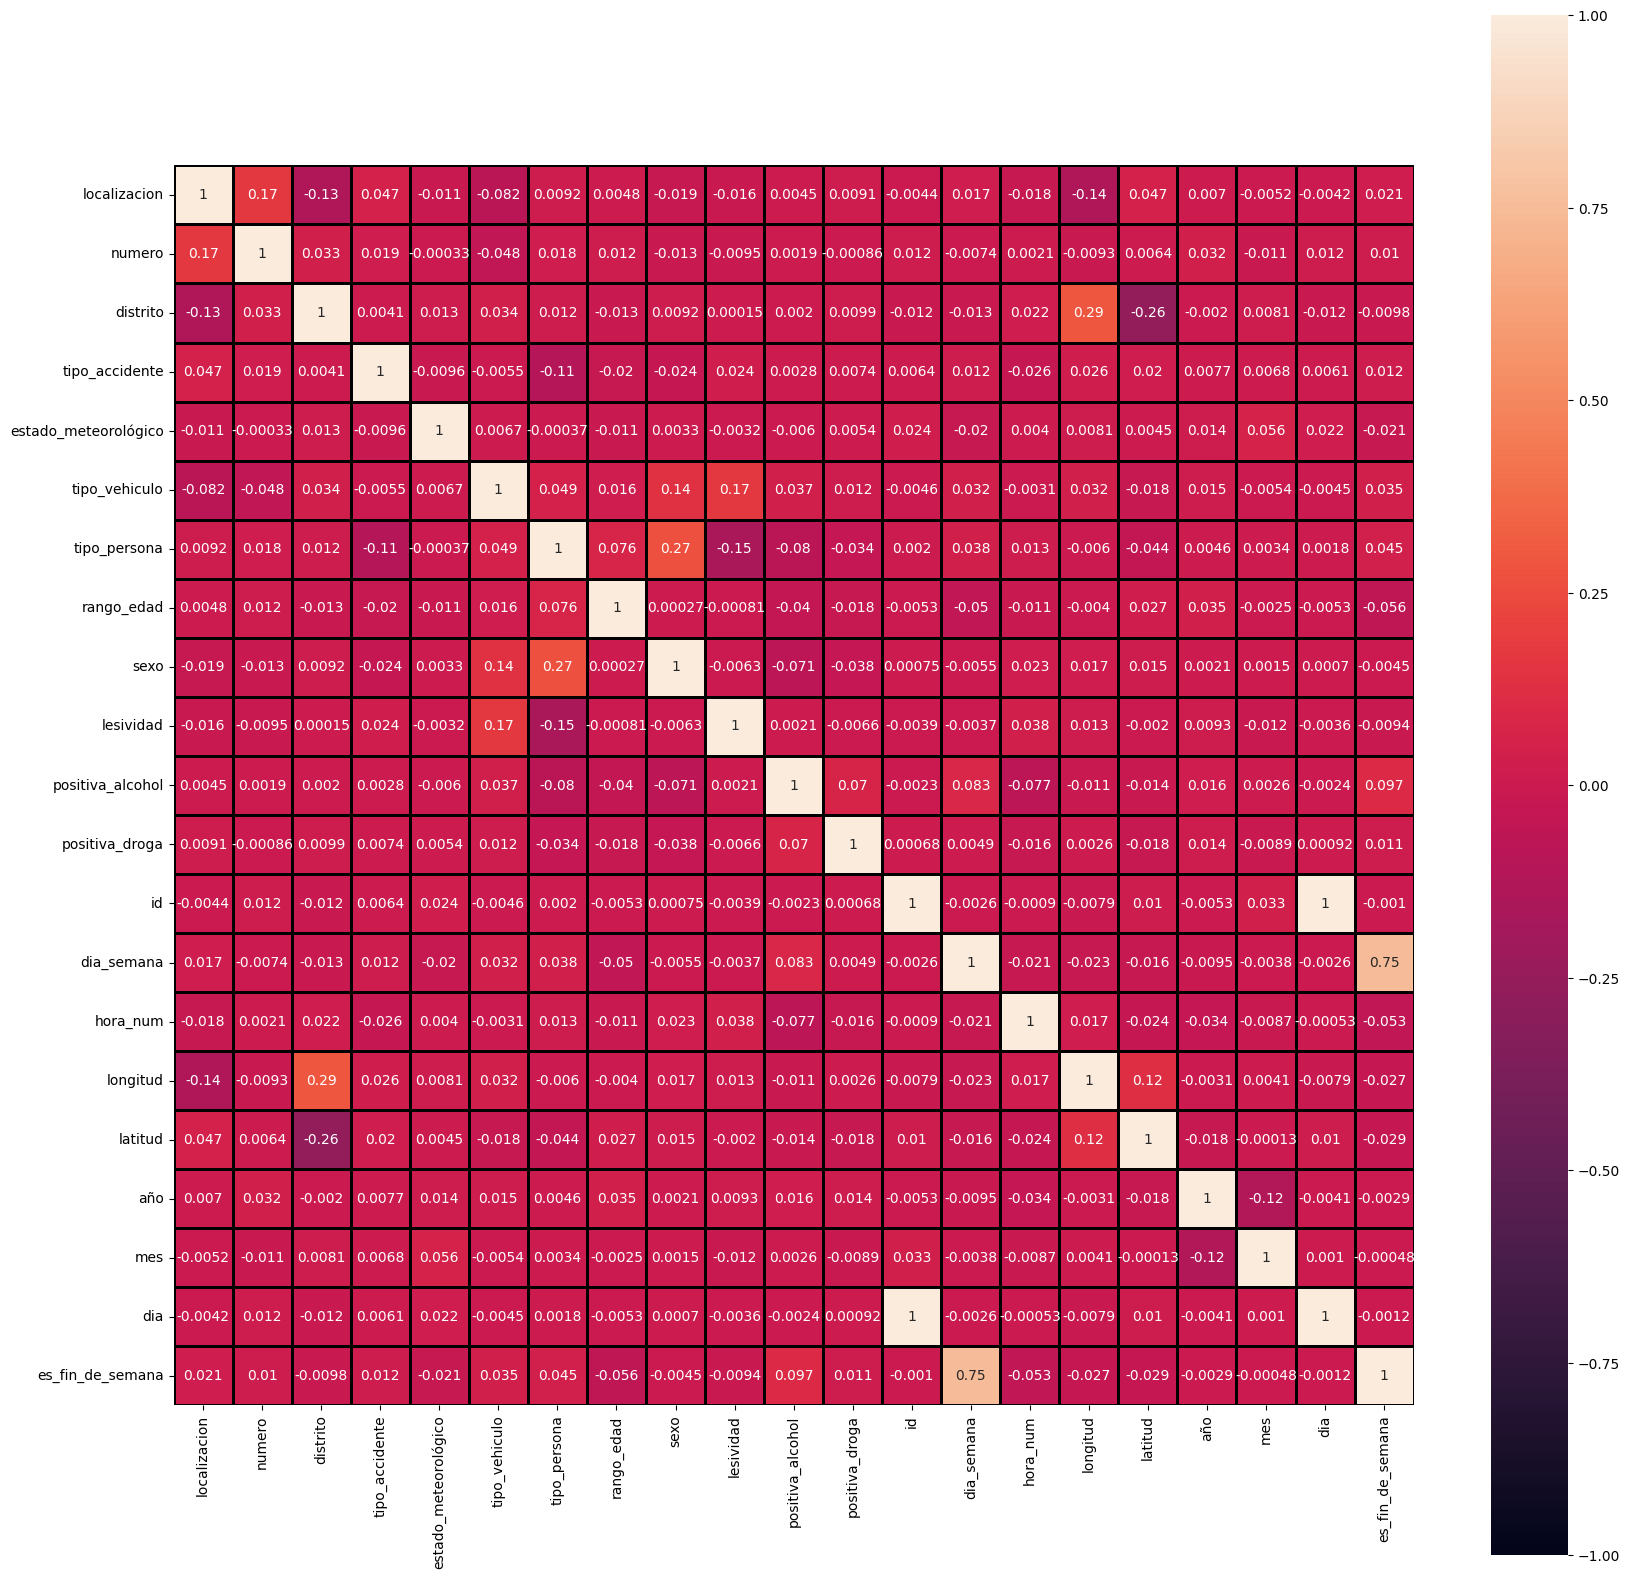

In [ ]:
fig=plt.gcf()
fig.set_size_inches(20,20)
fig=sns.heatmap(df_train.corr(),annot=True,linewidths=1,linecolor='k',square=True,mask=False, vmin=-1, vmax=1,cbar_kws={"orientation": "vertical"},cbar=True)

#SMOTE
Debido a que hemos notado que el dataset está sesgado de la lesividad 3, esto nos drá un problema a la hora de predecir, utilizaremos el SMOTE para balancear las clases

In [ ]:
from imblearn.combine import SMOTETomek
from collections import Counter
import pandas as pd

# Definir X (features) e y (target)
X = df_train.drop(columns=['lesividad'])
y = df_train['lesividad']

# Imprimir la distribución de clases antes del balanceo
print("Distribución original de clases:", Counter(y))

# Aplicar SMOTE-Tomek con estrategia automática
smt = SMOTETomek(sampling_strategy="auto", random_state=42)
X_balanced, y_balanced = smt.fit_resample(X, y)

# Confirmar la nueva distribución de clases después del balanceo
print("Distribución de clases después del balanceo:", Counter(y_balanced))

# Convertir los datos balanceados en un DataFrame para continuar el análisis
df_train_balanced = pd.DataFrame(X_balanced, columns=X.columns)
df_train_balanced['lesividad'] = y_balanced

# Mostrar las primeras filas del nuevo dataset balanceado
df_train_balanced.head()


Distribución original de clases: Counter({3: 66621, 2: 14399, 1: 1964})
Distribución de clases después del balanceo: Counter({1: 65313, 2: 59776, 3: 59458})


,localizacion,numero,distrito,tipo_accidente,estado_meteorológico,tipo_vehiculo,tipo_persona,rango_edad,sexo,positiva_alcohol,...,id,dia_semana,hora_num,longitud,latitud,año,mes,dia,es_fin_de_semana,lesividad
0,21312.0,1257.0,10.0,3.0,0.0,11.0,0.0,3.0,1.0,0.0,...,1,2,22,-3.795212,40.467771,2020,1,1,0,2
1,15671.0,971.0,12.0,4.0,0.0,32.0,0.0,2.0,0.0,0.0,...,3,2,9,-3.644627,40.387574,2020,1,1,0,3
2,7919.0,1760.0,9.0,4.0,0.0,32.0,0.0,2.0,0.0,0.0,...,4,2,12,-3.743364,40.404089,2020,1,1,0,3
3,2163.0,61.0,12.0,0.0,0.0,32.0,0.0,7.0,0.0,0.0,...,5,2,14,-3.682935,40.383372,2020,1,1,0,3
4,5436.0,1331.0,20.0,6.0,0.0,32.0,0.0,6.0,1.0,0.0,...,6,2,1,-3.689881,40.362096,2020,1,1,0,3


In [ ]:
df_train=df_train_balanced.copy()

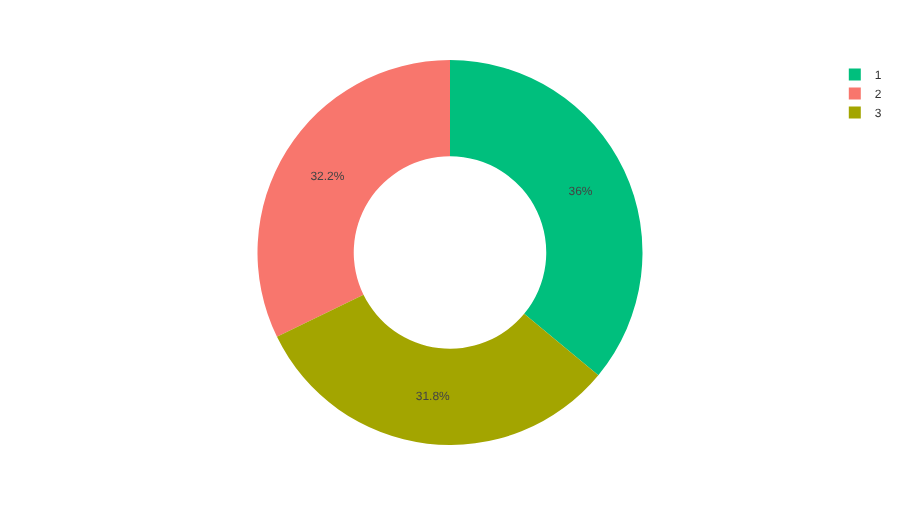

In [ ]:
# Análisis de los porcentajes de lesividades encontrados
px.pie(df_train,df_train['lesividad'],df_train['numero'],color='lesividad',template='ggplot2',hole=0.5)

#Contrucción del modelo y realizacion de predicciones

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import pandas as pd

# ---------------------------
# 1. Separar X (features) e y (variable objetivo)
# ---------------------------
# Se asume que df_train ya contiene todas las columnas preprocesadas y la columna 'lesividad'
X = df_train.drop('lesividad', axis=1)
y = df_train['lesividad']

# ---------------------------
# 2. Dividir en 80% entrenamiento y 20% validación (estratificado)
# ---------------------------
x_train, x_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"📌 Tamaño de x_train: {x_train.shape}")
print(f"📌 Tamaño de x_val: {x_val.shape}")

# ---------------------------
# 3. Entrenar el modelo sin búsqueda de hiperparámetros
# ---------------------------
# Se utiliza class_weight='balanced' para tratar el desbalance de clases
clf = RandomForestClassifier(class_weight='balanced', random_state=42)
clf.fit(x_train, y_train)

# ---------------------------
# 4. Evaluar el modelo en el conjunto de validación
# ---------------------------
y_pred_val = clf.predict(x_val)

print("\n🔹 Matriz de Confusión:")
print(confusion_matrix(y_val, y_pred_val))
print("\n🔹 Reporte de Clasificación:")
print(classification_report(y_val, y_pred_val))
print("Accuracy:", round(accuracy_score(y_val, y_pred_val), 2))

# ---------------------------
# 5. Predecir en el conjunto df_test
# ---------------------------
# Se asume que df_test ya está preprocesado de forma idéntica a df_train
y_pred_test = clf.predict(df_test)
print("✅ Predicciones en df_test completadas.")

# ---------------------------
# 6. Guardar las predicciones en un CSV
# ---------------------------
# Se asume que df_test contiene una columna 'id'
df_predictions = pd.DataFrame({
    'id': df_test['id'],
    'lesividad': y_pred_test
})

df_predictions.to_csv("predicciones_df_test.csv", index=False)
print("✅ Predicciones guardadas en 'predicciones_df_test.csv'")


📌 Tamaño de x_train: (147637, 20)
📌 Tamaño de x_val: (36910, 20)

🔹 Matriz de Confusión:
[[12680   215   168]
 [  769  9862  1324]
 [   86   575 11231]]

🔹 Reporte de Clasificación:
              precision    recall  f1-score   support

           1       0.94      0.97      0.95     13063
           2       0.93      0.82      0.87     11955
           3       0.88      0.94      0.91     11892

    accuracy                           0.92     36910
   macro avg       0.92      0.91      0.91     36910
weighted avg       0.92      0.92      0.91     36910

Accuracy: 0.92
✅ Predicciones en df_test completadas.
✅ Predicciones guardadas en 'predicciones_df_test.csv'


#Generar csv de predicciones del test

In [ ]:
import pandas as pd

# 🔹 1. Asegurar que df_test tiene la columna 'id'
if 'id' not in df_test.columns:
    raise ValueError("El conjunto de prueba (df_test) no tiene la columna 'id'.")

# 🔹 2. Crear el DataFrame con las predicciones
df_predictions = pd.DataFrame({
    'id': df_test['id'],  # Usar la columna 'id' de df_test
    'lesividad': y_pred_test    # Predicciones generadas
})

# 🔹 3. Guardar el archivo CSV con el formato requerido
df_predictions.to_csv("predicciones_df_test.csv", index=False)

print("✅ Predicciones guardadas en 'predicciones_df_test.csv'")

✅ Predicciones guardadas en 'predicciones_df_test.csv'


In [ ]:
from google.colab import files
files.download("predicciones_df_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#5. Conclusiones

-Se realizó una limpieza y transformación completa de los datos.

-Se aplicó SMOTE para balancear la variable lesividad, mejorando la representatividad de clases minoritarias.

-Se entrenó un modelo Random Forest que mostró buenos resultados en la clase mayoritaria pero dificultades en la predicción de clases menos frecuentes.

-El modelo a pesar de que resulta bastante bueno en cuanto a medidas de predicción, al hacer las predicciones es un 10% peor de lo esperado.

-Un modelo más preciso podría ayudar a la toma de decisiones en políticas de seguridad vial y asignación de recursos para la prevención de accidentes.

-Se podría integrar en sistemas de predicción en tiempo real para ayudar a las autoridades a identificar zonas de alto riesgo.




#EXPERIENCIA PERSONAL

Enfrentarme a este desafío sin experiencia previa ha sido una de las experiencias más enriquecedoras que he vivido. Cada obstáculo fue una oportunidad de aprendizaje, y aunque el proceso fue exigente, la satisfacción de avanzar y descubrir nuevas capacidades lo hizo invaluable. Este reto no solo me permitió desarrollar habilidades en análisis de datos y modelado predictivo, sino que también reforzó mi pasión por la inteligencia artificial. Más allá de los resultados, me quedo con la satisfacción de haber aprendido y disfrutado cada paso del proceso.